# ИЗ-4. Визуализация и разведочный анализ

**Окулова Александра, ИТ-14, вариант 16**

Перед сдачей: **Kernel → Restart & Run All**. Работа, которая так не проходит,
не проверяется. Выводы ячеек должны остаться в файле — ноутбук с пустыми
выводами смотреть не в чем.

Файл называется `ИЗ-4_Фамилия_Имя_вариантNN.ipynb`, сдача через Moodle.


## Настройка

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42                      # одно зерно на всю работу
np.random.seed(SEED)
pd.set_option("display.width", 110)
pd.set_option("display.max_columns", 20)

df = pd.read_csv("data.csv")    # файл лежит рядом с ноутбуком
df.shape


(9000, 21)

## ● Пункт 1. Распределение главной величины

<sub>обязательный пункт · 1 балл</sub>

Главная величина: True_vertical_depth
Наблюдений с глубиной: 6467 из 9000
Пропусков: 2533
Минимум: 1, максимум: 7485
Среднее: 1453.58, медиана: 1322.00
Q1: 1167, Q3: 1530
Корзин по Стёрджесу: 14
Корзин по Фридману — Дьяконису: 193
Отношение max/min: 7485.00
Число порядков: 3.8742
Асимметрия до логарифма: 3.5131
Асимметрия после логарифма: -1.0565
Максимальная корзина: 1070–1605 футов, наблюдений: 4034
Глубина от 4000 футов: 192 скважин (2.97%)
Типы скважин в правом хвосте:
Slant
Vertical    192
Name: count, dtype: int64


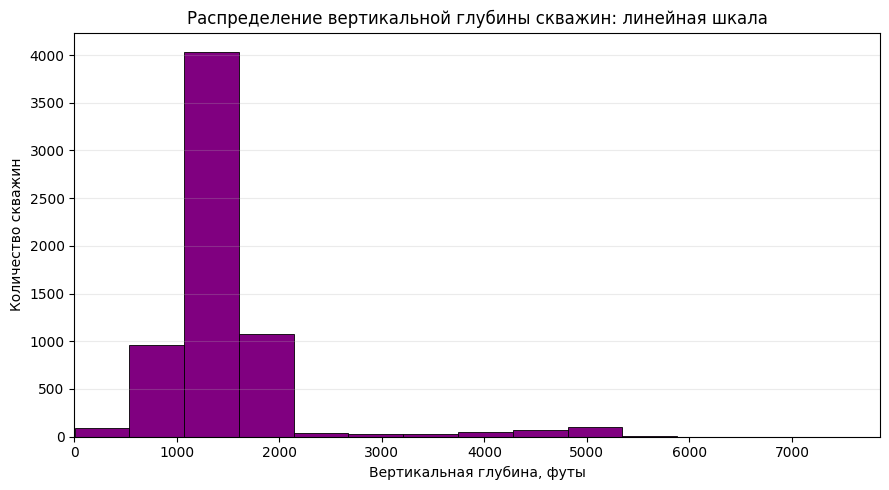

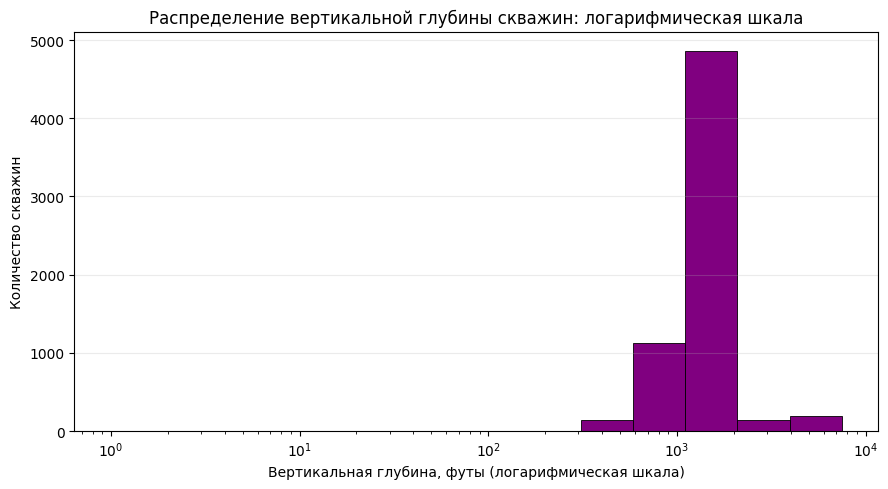

In [2]:
# Пункт 1: код

main_col = "True_vertical_depth"
group_col = "confid"
x = df[main_col].dropna().to_numpy(dtype=float)
n = len(x)

# Число корзин по двум правилам
k_sturges = len(np.histogram_bin_edges(x, bins="sturges")) - 1
k_fd = len(np.histogram_bin_edges(x, bins="fd")) - 1

# Диапазон значений
minimum = x.min()
maximum = x.max()
ratio = maximum / minimum
orders = np.log10(ratio)

# Коэффициент асимметрии
def asymmetry(a):
    centered = a - a.mean()
    m2 = np.mean(centered ** 2)
    m3 = np.mean(centered ** 3)
    return m3 / (m2 ** 1.5) if m2 > 0 else 0.0

skew_before = asymmetry(x)
skew_after = asymmetry(np.log(x))

# Описательная статистика
q1, median, q3 = np.quantile(x, [0.25, 0.5, 0.75])
hist_counts, edges = np.histogram(x, bins=k_sturges)
peak_bin = hist_counts.argmax()

# Скважины в правом хвосте распределения
deep = df[df[main_col] >= 4000]

print("Главная величина:", main_col)
print(f"Наблюдений с глубиной: {n} из {len(df)}")
print(f"Пропусков: {df[main_col].isna().sum()}")
print(f"Минимум: {minimum:.0f}, максимум: {maximum:.0f}")
print(f"Среднее: {x.mean():.2f}, медиана: {median:.2f}")
print(f"Q1: {q1:.0f}, Q3: {q3:.0f}")
print(f"Корзин по Стёрджесу: {k_sturges}")
print(f"Корзин по Фридману — Дьяконису: {k_fd}")
print(f"Отношение max/min: {ratio:.2f}")
print(f"Число порядков: {orders:.4f}")
print(f"Асимметрия до логарифма: {skew_before:.4f}")
print(f"Асимметрия после логарифма: {skew_after:.4f}")
print(
    f"Максимальная корзина: "
    f"{edges[peak_bin]:.0f}–{edges[peak_bin + 1]:.0f} футов, "
    f"наблюдений: {hist_counts[peak_bin]}"
)
print(
    f"Глубина от 4000 футов: {len(deep)} скважин "
    f"({len(deep) / n * 100:.2f}%)"
)
print("Типы скважин в правом хвосте:")
print(deep["Slant"].value_counts(dropna=False))

# Гистограмма с линейной шкалой
plt.figure(figsize=(9, 5))
plt.hist(
    x,
    bins=k_sturges,
    edgecolor="black",
    linewidth=0.6,
    color="purple"
)

plt.title("Распределение вертикальной глубины скважин: линейная шкала")
plt.xlabel("Вертикальная глубина, футы")
plt.ylabel("Количество скважин")
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Гистограмма с логарифмической шкалой
log_edges = np.geomspace(minimum, maximum, k_sturges + 1)
plt.figure(figsize=(9, 5))
plt.hist(
    x,
    bins=log_edges,
    edgecolor="black",
    linewidth=0.6,
    color="purple"
)

plt.xscale("log")
plt.title("Распределение вертикальной глубины скважин: логарифмическая шкала")
plt.xlabel("Вертикальная глубина, футы (логарифмическая шкала)")
plt.ylabel("Количество скважин")
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


**Ответ.**

> Я выбрала 14 корзин по Стёрджесу вместо 193 по Фридману - Дьяконису, поскольку так лучше видно общую форму распределения. Основная часть глубин сосредоточена около 1300 футов, а распределение имеет длинный правый хвост. Из 6467 скважин с известной глубиной только 192 имеют глубину от 4000 футов. График показывает распределение глубин, но сам по себе не объясняет причины различий между скважинами. Отношение максимальной глубины к минимальной равно 7485, то есть данные охватывают 3,8742 десятичных порядка. Поэтому я построила линейную и логарифмическую гистограммы. Для отображения типичных глубин линейная шкала оказалась удобнее. После логарифмирования асимметрия изменилась с 3,5131 до -1,0565, то есть уменьшилась по модулю.

## ● Пункт 2. Разброс по группам

<sub>обязательный пункт · 1 балл</sub>

Статистика по группам:
                                       size  count       mean  median       std  расхождение
confid                                                                                      
Application Received or Permit Issued   145     23  1948.4348  1821.0  693.1939       0.1838
No                                     8401   6001  1408.6889  1303.0  660.8090       0.1599
Released                                453    443  2035.9255  1874.0  903.1901       0.1793

Группа с наибольшим расхождением: Application Received or Permit Issued
Расхождение: 0.1838
Известных глубин: 23


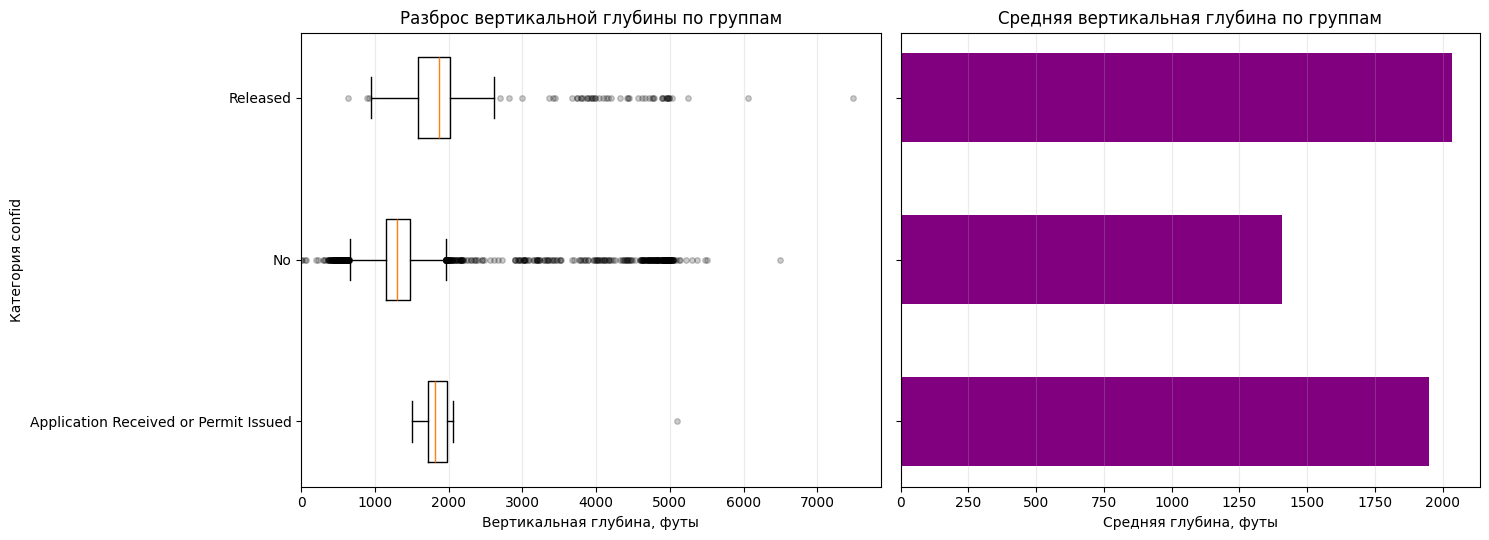

In [3]:
# Пункт 2: код

value_col = "True_vertical_depth"
category_col = "confid"

# Статистика по группам
by_group = df.dropna(subset=[category_col]).groupby(category_col)[value_col]
stats2 = by_group.agg(["size", "count", "mean", "median"])
stats2["std"] = by_group.std(ddof=0)

# Расхождение среднего и медианы
stats2["расхождение"] = np.where(
    stats2["std"] > 0,
    (stats2["mean"] - stats2["median"]).abs()
    / stats2["std"].replace(0, np.nan),
    0.0
)
print("Статистика по группам:")
print(stats2.round(4).to_string())

# Наибольшее расхождение
worst_group = stats2["расхождение"].idxmax()
print("\nГруппа с наибольшим расхождением:", worst_group)
print("Расхождение:", round(stats2.loc[worst_group, "расхождение"], 4))
print("Известных глубин:", int(stats2.loc[worst_group, "count"]))

# Данные для графиков
graph_df = df[[category_col, value_col]].dropna()

group_names = list(stats2.index)
positions = np.arange(1, len(group_names) + 1)

box_data = [
    graph_df.loc[graph_df[category_col] == name, value_col]
    for name in group_names
]

# Два графика рядом
fig, (ax_box, ax_mean) = plt.subplots(
    1, 2, figsize=(15, 5.5), sharey=True
)

# Ящики с усами
ax_box.boxplot(
    box_data,
    positions=positions,
    vert=False,
    widths=0.5,
    showfliers=True,
    manage_ticks=False,
    flierprops={
        "marker": "o",
        "markersize": 4,
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "alpha": 0.2
    }
)
ax_box.set_yticks(positions, labels=group_names)
ax_box.set_title("Разброс вертикальной глубины по группам")
ax_box.set_xlabel("Вертикальная глубина, футы")
ax_box.set_ylabel("Категория confid")
ax_box.set_xlim(left=0)
ax_box.grid(axis="x", alpha=0.25)

# Диаграмма средних
ax_mean.barh(
    positions,
    stats2["mean"].to_numpy(),
    height=0.55,
    color="purple"
)

ax_mean.set_title("Средняя вертикальная глубина по группам")
ax_mean.set_xlabel("Средняя глубина, футы")
ax_mean.set_xlim(left=0)
ax_mean.tick_params(axis="y", labelleft=False)
ax_mean.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()




**Ответ.**

> Я сравнила распределение True_vertical_depth по трём категориям confid. Наибольшее расхождение среднего и медианы получилось в группе Application Received or Permit Issued = 0,1838. В ней среднее равно 1948,43 фута, а медиана = 1821 фут. Однако из 145 записей глубина известна только у 23, поэтому выводы по этой группе менее надёжны, чем по No (6001 наблюдение) и Released (443 наблюдения). Диаграмма средних показывает, что средняя глубина в Released больше, чем в No: 2035,93 против 1408,69 фута. Но ящики с усами показывают, что распределения глубин перекрываются и внутри групп встречаются отдельные очень глубокие скважины. Поэтому по одной диаграмме средних можно было бы ошибочно заключить, что все скважины Released глубже скважин No. Я считаю группу из 23 наблюдений небольшой для уверенного описания распределения, особенно с учётом большого количества пропусков. Для более надёжного сравнения нужно иметь больше наблюдений, а также учитывать разброс и выбросы, а не только среднее.

## ● Пункт 3. Связь двух величин

<sub>обязательный пункт · 1 балл</sub>

Наблюдений с обеими глубинами: 6463
Пирсон: 0.997721
Спирмен: 0.999980
Модуль разности: 0.002259
Совпадающих глубин: 6454
Различающихся глубин: 9

Скважины с расхождением глубин:
    API_WellNo      Slant  True_vertical_depth  Measured_depth  Depth_difference
31003004640000   Vertical               1975.0          4924.0            2949.0
31003280180000 Horizontal               1750.0          4154.0            2404.0
31003652040000   Vertical               1130.0          1050.0              80.0
31003233490000   Vertical               1282.0          1310.0              28.0
31003603660000   Vertical               1960.0          1945.0              15.0
31003233740000   Vertical               1420.0          1428.0               8.0
31003233730000   Vertical               1972.0          1970.0               2.0
31003235350000   Vertical               1802.0          1800.0               2.0
31003235360000   Vertical               1401.0          1400.0               1.0


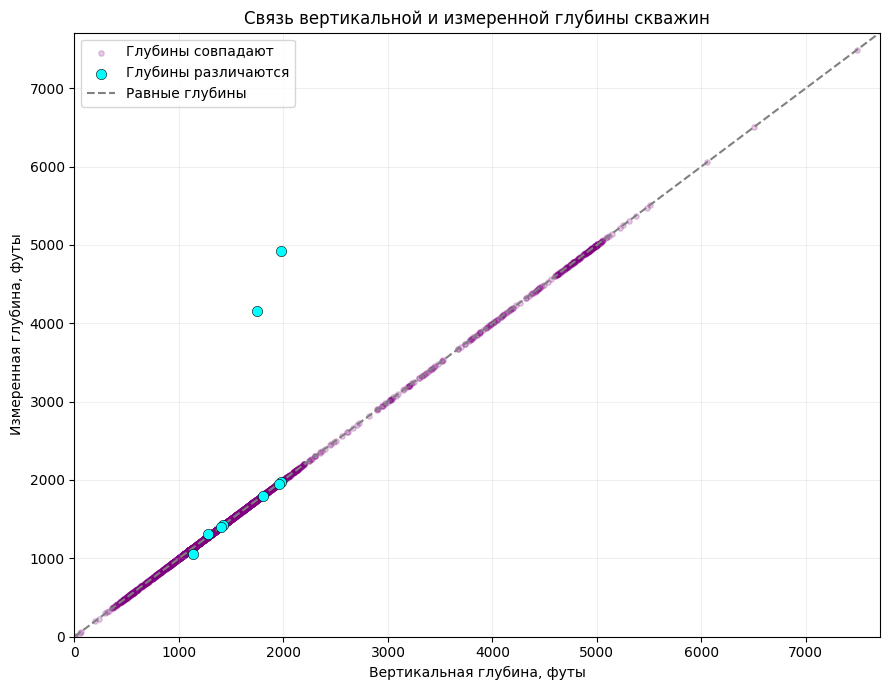

In [4]:
# Пункт 3: код

x_col = "True_vertical_depth"
y_col = "Measured_depth"

# Оставляем строки, где известны обе глубины
pair_df = df[
    [x_col, y_col, "Slant", "API_WellNo"]
].dropna(subset=[x_col, y_col]).copy()

# Коэффициенты корреляции
pearson = pair_df[x_col].corr(pair_df[y_col], method="pearson")
spearman = pair_df[x_col].corr(pair_df[y_col], method="spearman")
correlation_gap = abs(pearson - spearman)

# Скважины с разными глубинами
pair_df["Depth_difference"] = (
    pair_df[y_col] - pair_df[x_col]
).abs()

same_mask = pair_df["Depth_difference"] == 0
different_mask = pair_df["Depth_difference"] > 0

print("Наблюдений с обеими глубинами:", len(pair_df))
print(f"Пирсон: {pearson:.6f}")
print(f"Спирмен: {spearman:.6f}")
print(f"Модуль разности: {correlation_gap:.6f}")
print("Совпадающих глубин:", same_mask.sum())
print("Различающихся глубин:", different_mask.sum())
print("\nСкважины с расхождением глубин:")
print(
    pair_df.loc[
        different_mask,
        ["API_WellNo", "Slant", x_col, y_col, "Depth_difference"]
    ].sort_values(
        "Depth_difference", ascending=False
    ).to_string(index=False)
)

# Точечная диаграмма
fig, ax = plt.subplots(figsize=(9, 7))

# Скважины с одинаковыми глубинами
ax.scatter(
    pair_df.loc[same_mask, x_col],
    pair_df.loc[same_mask, y_col],
    color="purple",
    s=15,
    alpha=0.20,
    label="Глубины совпадают"
)

# Скважины с различающимися глубинами
ax.scatter(
    pair_df.loc[different_mask, x_col],
    pair_df.loc[different_mask, y_col],
    color="cyan",
    s=55,
    edgecolors="black",
    linewidths=0.4,
    label="Глубины различаются",
    zorder=3
)

# Линия равенства двух глубин
limit = max(pair_df[x_col].max(), pair_df[y_col].max()) * 1.03

ax.plot(
    [0, limit], [0, limit],
    "--", color="gray",
    label="Равные глубины"
)

ax.set_title("Связь вертикальной и измеренной глубины скважин")
ax.set_xlabel("Вертикальная глубина, футы")
ax.set_ylabel("Измеренная глубина, футы")

ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()


**Ответ.**

> Я построила точечную диаграмму зависимости Measured_depth от True_vertical_depth. Коэффициент Пирсона равен 0,9977, Спирмена - 0,99998, модуль их разности составляет 0,0023. Они практически совпадают, поэтому зависимость очень сильная, почти линейная и возрастающая. Из 6463 скважин с известными глубинами у 6454 значения полностью совпадают. Однако есть 9 скважин с расхождениями, наиболее заметные - с разницей 2949 и 2404 фута. Одну из них можно объяснить горизонтальной траекторией скважины, а другое большое расхождение у вертикальной скважины может указывать на неточность данных. График показывает сильную связь между двумя измерениями глубины, но не доказывает причинно-следственную зависимость. Оба признака описывают глубину одной скважины, поэтому их связь может объясняться общей физической характеристикой объекта и способом измерения.

## ● Пункт 4. Категории и таблица сопряжённости

<sub>обязательный пункт · 1 балл</sub>

Таблица сопряжённости (количество скважин):
Original_well_type                     GD  GE  GW  IW  MS    NL   OD  OW  ST
confid                                                                      
Application Received or Permit Issued   0   0   4   2   1     5  132   1   0
No                                      0   0   2  33   1  8028  334   1   2
Released                                4   1   5   0   2   131  298   4   8

Всего учтено скважин: 8999

Клетка: Released × OD
Число скважин: 298
От всей таблицы: 3.31%
От своей строки: 65.78%
От своего столбца: 39.01%


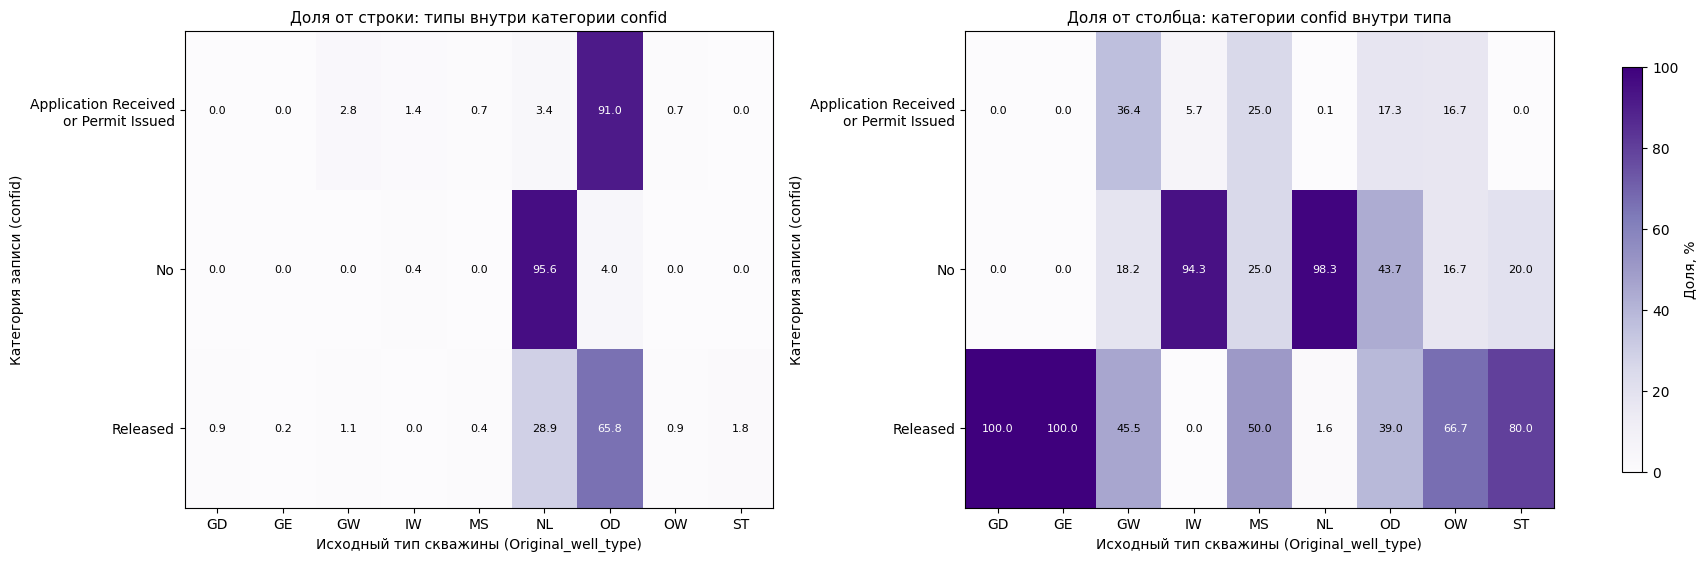

In [5]:
# Пункт 4: код

row_col = "confid"
col_col = "Original_well_type"

# Убираем строки с пропусками в выбранных категориях
data4 = df[[row_col, col_col]].dropna()

# Таблица количества скважин для каждой пары категорий
counts4 = pd.crosstab(data4[row_col], data4[col_col])

# Проценты от своей строки и от своего столбца
row_pct4 = counts4.div(counts4.sum(axis=1), axis=0) * 100
col_pct4 = counts4.div(counts4.sum(axis=0), axis=1) * 100

print("Таблица сопряжённости (количество скважин):")
print(counts4.to_string())
print("\nВсего учтено скважин:", counts4.to_numpy().sum())

# Выбранная клетка
chosen_row = "Released"
chosen_col = "OD"
cell_count = counts4.loc[chosen_row, chosen_col]

whole_pct = cell_count / counts4.to_numpy().sum() * 100
within_row_pct = row_pct4.loc[chosen_row, chosen_col]
within_col_pct = col_pct4.loc[chosen_row, chosen_col]

print(f"\nКлетка: {chosen_row} × {chosen_col}")
print("Число скважин:", cell_count)
print(f"От всей таблицы: {whole_pct:.2f}%")
print(f"От своей строки: {within_row_pct:.2f}%")
print(f"От своего столбца: {within_col_pct:.2f}%")

fig, axes = plt.subplots(
    1, 2, figsize=(17, 5.5), constrained_layout=True
)

labels_y = [
    name.replace(
        "Application Received or Permit Issued",
        "Application Received\nor Permit Issued"
    )
    for name in counts4.index
]

for ax, values, title in zip(
    axes,
    (row_pct4, col_pct4),
    (
        "Доля от строки: типы внутри категории confid",
        "Доля от столбца: категории confid внутри типа"
    )
):
    image = ax.imshow(
        values.to_numpy(),
        cmap="Purples",
        vmin=0,
        vmax=100,
        aspect="auto"
    )

    ax.set_xticks(np.arange(len(values.columns)))
    ax.set_xticklabels(values.columns)
    ax.set_yticks(np.arange(len(values.index)))
    ax.set_yticklabels(labels_y)

    ax.set_xlabel("Исходный тип скважины (Original_well_type)")
    ax.set_ylabel("Категория записи (confid)")
    ax.set_title(title, fontsize=11)

    # Проценты внутри клеток
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            number = values.iloc[i, j]

            ax.text(
                j, i, f"{number:.1f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if number > 55 else "black"
            )

fig.colorbar(
    image, ax=axes,
    label="Доля, %",
    shrink=0.85
)

plt.show()


**Ответ.**

> Я построила две тепловые карты по признакам confid и Original_well_type. Первая показывает распределение исходных типов скважин внутри каждой категории confid, а вторая распределение категорий confid внутри каждого исходного типа. Для клетки Released × OD получилось 298 скважин. Это 3,31% всей таблицы, 65,78% категории Released и 39,01% исходного типа OD. Первая карта отвечает на вопрос, какие типы скважин преобладают внутри выбранной категории confid. Вторая отвечает на вопрос, какие категории confid характерны для конкретного исходного типа скважины. Поэтому проценты на картах отличаются. Карты показывают связь между категориальными признаками, но не доказывают, что один признак является причиной другого. Редкие исходные типы представлены очень небольшим количеством скважин, поэтому большие проценты в таких клетках нужно интерпретировать осторожно.

## ○ Пункт 5. Проверка на парадокс Симпсона

<sub>дополнительный пункт · 1 балл</sub>

По всем данным:
Количество: 6463
Пирсон: 0.997721
Спирмен: 0.999980

Корреляция внутри групп:
                               Группа  Количество   Пирсон  Спирмен
Application Received or Permit Issued          23 1.000000 1.000000
                                   No        5997 0.998346 0.999994
                             Released         443 0.992087 0.994583

Есть противоположное направление связи: нет


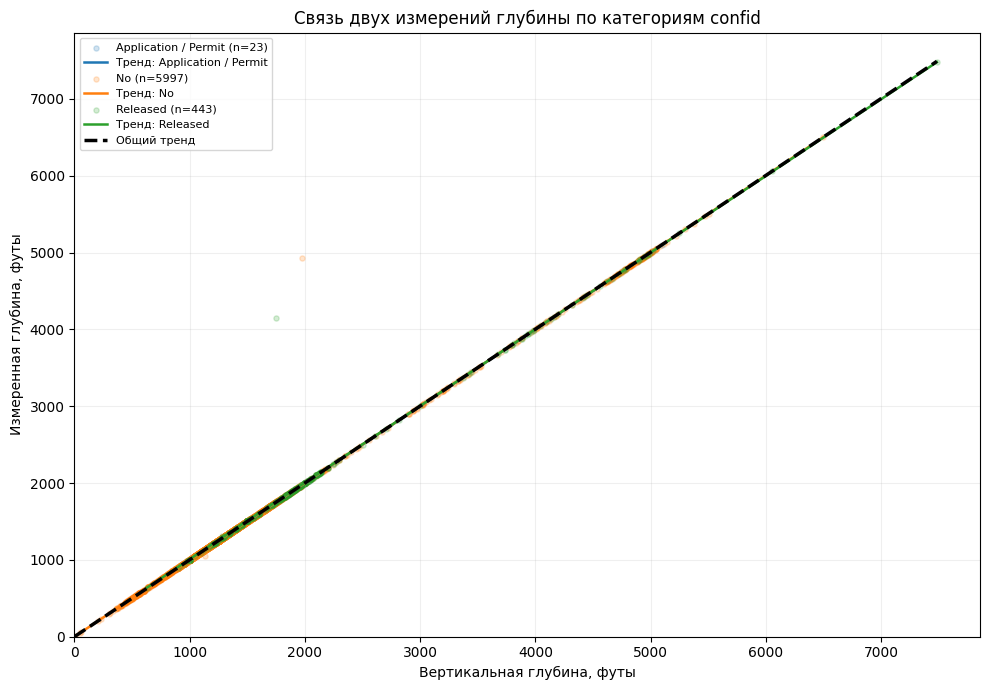

In [6]:
# Пункт 5: код

x_col = "True_vertical_depth"
y_col = "Measured_depth"
group_col = "confid"

# Оставляем строки с известными глубинами и категорией
data5 = df[[x_col, y_col, group_col]].dropna().copy()

# Общая корреляция
pearson_all = data5[x_col].corr(data5[y_col], method="pearson")
spearman_all = data5[x_col].corr(data5[y_col], method="spearman")

print("По всем данным:")
print("Количество:", len(data5))
print(f"Пирсон: {pearson_all:.6f}")
print(f"Спирмен: {spearman_all:.6f}")

# Корреляции и тренды внутри групп
results5 = []
fig, ax = plt.subplots(figsize=(10, 7))
colors = plt.get_cmap("tab10")

for i, (name, group) in enumerate(data5.groupby(group_col)):
    pearson = group[x_col].corr(group[y_col], method="pearson")
    spearman = group[x_col].corr(group[y_col], method="spearman")

    results5.append([name, len(group), pearson, spearman])

    short_name = (
        "Application / Permit"
        if name == "Application Received or Permit Issued"
        else name
    )
    color = colors(i)

    # Точки каждой группы своим цветом
    ax.scatter(
        group[x_col], group[y_col],
        s=14, alpha=0.20, color=color,
        label=f"{short_name} (n={len(group)})"
    )

    # Отдельная линия тренда для группы
    slope, intercept = np.polyfit(group[x_col], group[y_col], 1)
    line_x = np.array([group[x_col].min(), group[x_col].max()])

    ax.plot(
        line_x, slope * line_x + intercept,
        color=color, linewidth=1.8,
        label=f"Тренд: {short_name}"
    )

# Общая линия тренда
slope_all, intercept_all = np.polyfit(
    data5[x_col], data5[y_col], 1
)

line_x = np.array([data5[x_col].min(), data5[x_col].max()])

ax.plot(
    line_x, slope_all * line_x + intercept_all,
    "k--", linewidth=2.5, label="Общий тренд"
)

# Таблица результатов
result5 = pd.DataFrame(
    results5,
    columns=["Группа", "Количество", "Пирсон", "Спирмен"]
)

print("\nКорреляция внутри групп:")
print(result5.round(6).to_string(index=False))

# Проверка, изменилось ли направление связи
opposite = ((result5["Пирсон"] * pearson_all) < 0).any()

print(
    "\nЕсть противоположное направление связи:",
    "да" if opposite else "нет"
)

ax.set_title("Связь двух измерений глубины по категориям confid")
ax.set_xlabel("Вертикальная глубина, футы")
ax.set_ylabel("Измеренная глубина, футы")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()


**Ответ.**

> Я проверила наличие парадокса Симпсона для связи между True_vertical_depth и Measured_depth, разделив скважины по категориям confid. По всем 6463 наблюдениям коэффициент Пирсона равен 0,997721. Внутри групп он также положительный: No - 0,998346 (5997 наблюдений), Released - 0,992087 (443 наблюдения), Application Received or Permit Issued - 1,000000 (23 наблюдения). Коэффициенты Спирмена также близки к единице. **Парадокс Симпсона не обнаружен**, поскольку направление связи во всех группах совпадает с общим. На графике это подтверждается практически совпадающими возрастающими линиями тренда. Это объясняется тем, что оба признака измеряют глубину одной скважины разными способами, поэтому их значения сильно связаны независимо от категории confid. При этом график не доказывает причинного влияния одной глубины на другую.

## ○ Пункт 6. Пропуски как объект визуализации

<sub>дополнительный пункт · 1 балл</sub>

Пропуски по столбцам:
                     Пропусков  Доля, %
Date_Spudded              7680    85.33
Proposed_depth            7630    84.78
Date_Well_Completed       6764    75.16
Elevation                 6493    72.14
Measured_depth            2533    28.14
True_vertical_depth       2533    28.14
Permit_Fee                  19     0.21
Company_name                15     0.17
Surface_Longitude            3     0.03
Surface_latitude             3     0.03
Slant                        1     0.01
Objective_formation          1     0.01
confid                       1     0.01
Well_Type                    0     0.00
API_WellNo                   0     0.00
y_clf                        0     0.00
row_id                       0     0.00
Original_well_type           0     0.00
County                       0     0.00
town                         0     0.00
Producing_formation          0     0.00

Самый неполный столбец: Date_Spudded
Пропусков: 7680 из 9000

Доля пропусков по y_clf:
y_clf
0   

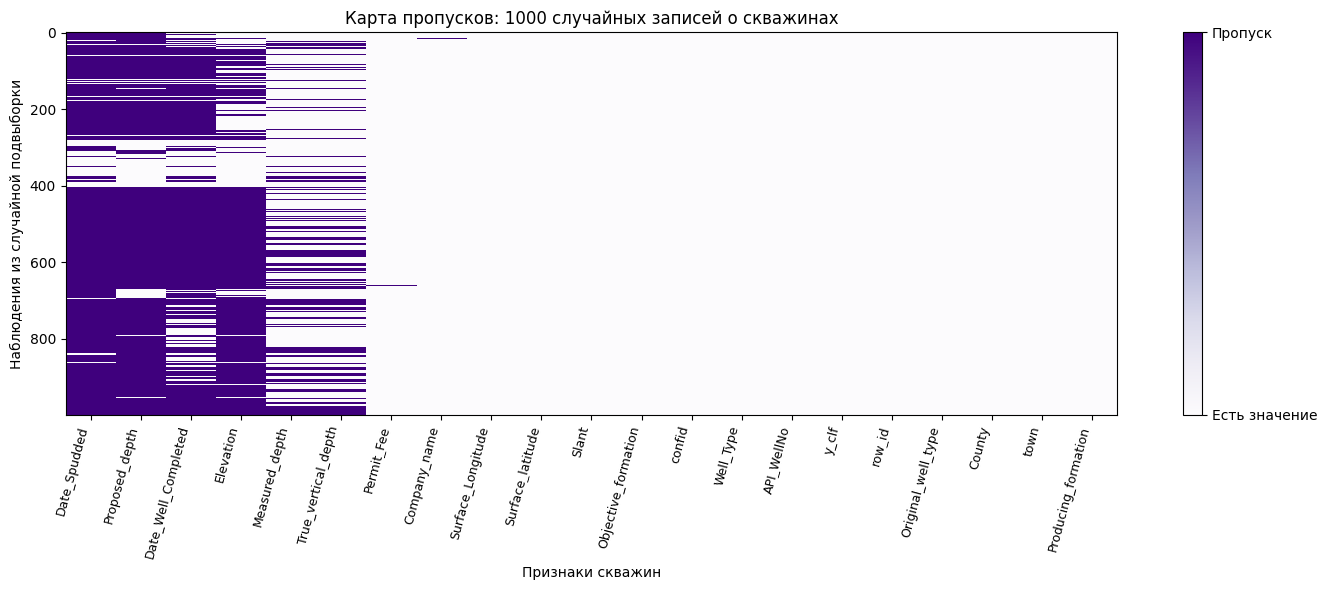

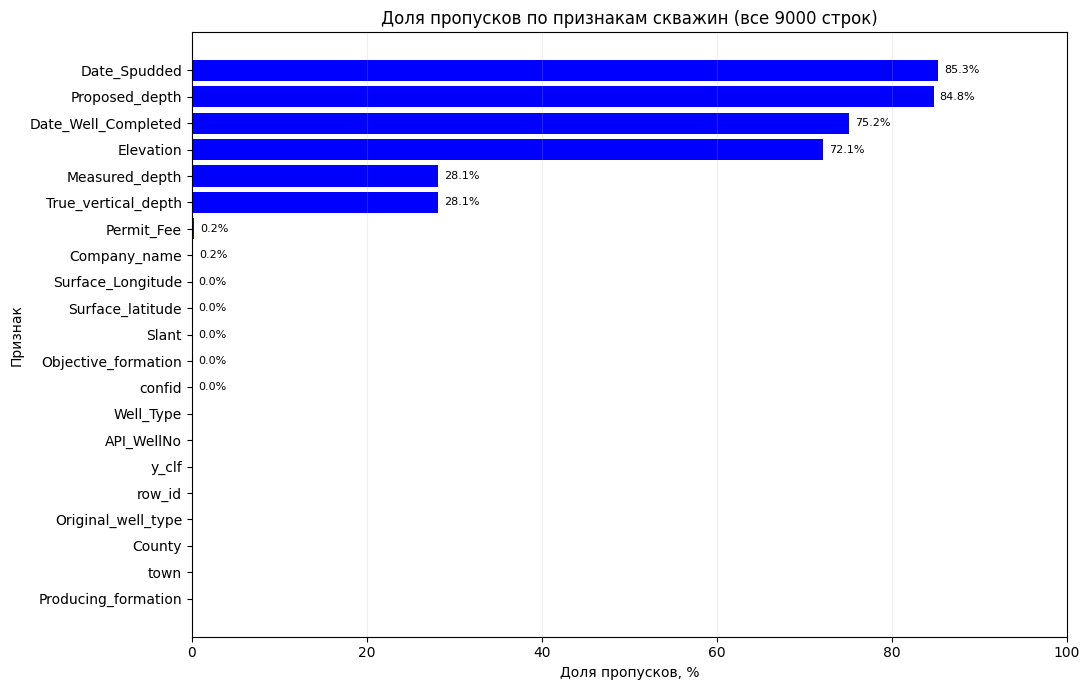

In [7]:
# Пункт 6: код

# Пропуски по каждому столбцу
missing6 = pd.DataFrame({
    "Пропусков": df.isna().sum(),
    "Доля, %": df.isna().mean() * 100
}).sort_values("Доля, %", ascending=False)

print("Пропуски по столбцам:")
print(missing6.round(2).to_string())

# Находим самый неполный столбец
worst_col6 = missing6.index[0]
mask6 = df[worst_col6].isna()

# Проверяем связь пропусков
missing_by_y6 = df.groupby("y_clf")[worst_col6].apply(
    lambda series: series.isna().mean() * 100
)
print("\nСамый неполный столбец:", worst_col6)
print(f"Пропусков: {mask6.sum()} из {len(df)}")
print("\nДоля пропусков по y_clf:")
print(missing_by_y6.round(2))

difference6 = abs(
    missing_by_y6.loc[0] - missing_by_y6.loc[1]
)
print(f"Разница долей: {difference6:.2f} п.п.")
print(
    "Полностью пустых строк:",
    df.isna().all(axis=1).sum()
)

# Карта пропусков
sample6 = df.sample(
    n=min(1000, len(df)),
    random_state=42
).sort_index()

map6 = sample6[missing6.index].isna().astype(int)
fig, ax = plt.subplots(figsize=(14, 6))

image = ax.imshow(
    map6.to_numpy(),
    cmap="Purples",
    vmin=0,
    vmax=1,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(np.arange(map6.shape[1]))
ax.set_xticklabels(
    map6.columns,
    rotation=75,
    ha="right",
    fontsize=9
)

ax.set_xlabel("Признаки скважин")
ax.set_ylabel("Наблюдения из случайной подвыборки")
ax.set_title(
    "Карта пропусков: 1000 случайных записей о скважинах"
)

cbar = fig.colorbar(image, ax=ax)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Есть значение", "Пропуск"])

plt.tight_layout()
plt.show()

#Доля пропусков по столбцам
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(
    missing6.index,
    missing6["Доля, %"],
    color="blue"
)

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Доля пропусков, %")
ax.set_ylabel("Признак")
ax.set_title(
    "Доля пропусков по признакам скважин (все 9000 строк)"
)
ax.grid(axis="x", alpha=0.2)

for i, value in enumerate(missing6["Доля, %"]):
    if value > 0:
        ax.text(
            value + 0.7,
            i,
            f"{value:.1f}%",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()


**Ответ.**

> Я построила карту пропусков по случайной подвыборке из 1000 скважин и столбиковую диаграмму долей пропусков по всем 9000 наблюдениям. На карте наиболее заметны вертикальные полосы, соответствующие столбцам с большим количеством отсутствующих данных. Больше всего пропусков в Date_Spudded - 85,33%, Proposed_depth - 84,78%, Date_Well_Completed - 75,16% и Elevation - 72,14%. Полностью пустых строк в таблице нет. Пропуски Date_Spudded связаны с признаком y_clf. Среди скважин с y_clf = 0 дата отсутствует в 91,63% случаев, а при y_clf = 1 - в 36,60%. Разница составляет 55,03 процентного пункта. Следовательно, пропуски распределены неслучайно относительно этого признака, и заполнение всех отсутствующих дат одним общим значением может исказить данные. Я бы сохранила сведения о наличии или отсутствии даты как отдельный признак. Для очень неполных столбцов дополнительно оценила бы необходимость их использования в моделировании. Карта показывает структуру пропусков и их совместное появление, но не устанавливает точную причину отсутствия данных. Также она не показывает некорректные значения, записанные вместо пропусков, например координаты (0, 0). Тёмные блоки показывают, что у части скважин одновременно отсутствуют несколько характеристик, прежде всего даты и глубины. Это указывает на совместное появление пропусков, но не позволяет установить их причину без дополнительного анализа.

## ○ Пункт 7. Много ли объясняет группировка

<sub>дополнительный пункт · 1 балл</sub>

Статистика по группам:
                                       size     mean  median
confid                                                      
No                                     6001  1408.69  1303.0
Application Received or Permit Issued    23  1948.43  1821.0
Released                                443  2035.93  1874.0

Число групп: 3
Общая сумма квадратов: 3160836340.15
Межгрупповая сумма квадратов: 167958503.81
Внутригрупповая сумма квадратов: 2992877836.34
eta²: 0.0531
Объяснённый разброс: 5.31%


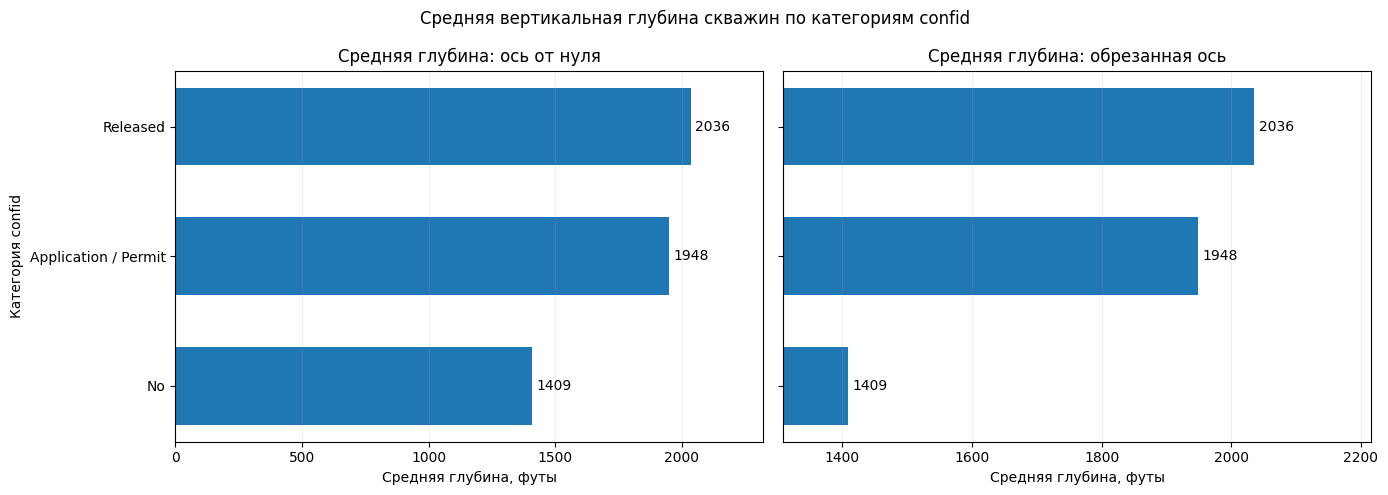

In [8]:
# Пункт 7: код

value_col = "True_vertical_depth"
group_col = "confid"

# Оставляем строки с известной глубиной и категорией
data7 = df[[group_col, value_col]].dropna()

# Размер и средняя глубина каждой группы
stats7 = (
    data7.groupby(group_col)[value_col]
    .agg(["size", "mean", "median"])
    .sort_values("mean")
)

# Общая сумма квадратов
overall_mean7 = data7[value_col].mean()

ss_total7 = (
    (data7[value_col] - overall_mean7) ** 2
).sum()

# Межгрупповая сумма квадратов
ss_between7 = (
    stats7["size"] *
    (stats7["mean"] - overall_mean7) ** 2
).sum()

# Внутригрупповая сумма квадратов
ss_within7 = ss_total7 - ss_between7

# Доля разброса, объясняемая группировкой
eta_squared7 = (
    ss_between7 / ss_total7 if ss_total7 > 0 else 0
)

print("Статистика по группам:")
print(stats7.round(2))
print("\nЧисло групп:", len(stats7))
print(f"Общая сумма квадратов: {ss_total7:.2f}")
print(f"Межгрупповая сумма квадратов: {ss_between7:.2f}")
print(f"Внутригрупповая сумма квадратов: {ss_within7:.2f}")
print(f"eta²: {eta_squared7:.4f}")
print(f"Объяснённый разброс: {eta_squared7 * 100:.2f}%")

# Два графика с разным началом оси X
names7 = [
    "Application / Permit"
    if name == "Application Received or Permit Issued"
    else name
    for name in stats7.index
]

means7 = stats7["mean"].to_numpy()
positions7 = np.arange(len(means7))

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(14, 5), sharey=True
)

for ax, title in [
    (ax1, "Средняя глубина: ось от нуля"),
    (ax2, "Средняя глубина: обрезанная ось")
]:
    bars = ax.barh(positions7, means7, height=0.6)

    ax.set_title(title)
    ax.set_xlabel("Средняя глубина, футы")
    ax.set_yticks(positions7, labels=names7)
    ax.grid(axis="x", alpha=0.2)
    ax.bar_label(bars, fmt="%.0f", padding=3)

# Первый график
ax1.set_xlim(0, means7.max() * 1.14)
ax1.set_ylabel("Категория confid")

# Второй график
ax2.set_xlim(
    means7.min() - 100,
    means7.max() + 180
)
ax2.tick_params(axis="y", labelleft=False)

fig.suptitle(
    "Средняя вертикальная глубина скважин по категориям confid"
)

plt.tight_layout()
plt.show()


**Ответ.**

> Я сравнила среднюю вертикальную глубину скважин в категориях confid на двух диаграммах с разным масштабом оси. На графике с осью от нуля различия выглядят умеренными, а на графике с обрезанной осью они кажутся намного значительнее, хотя исходные значения одинаковые. Средняя глубина составляет 1408,69 фута для No, 1948,43 для Application Received or Permit Issued и 2035,93 для Released. Общая сумма квадратов равна 3 160 836 340,15, межгрупповая = 167 958 503,81, внутригрупповая = 2 992 877 836,34. Коэффициент η² равен 0,0531. Следовательно, группировка по confid объясняет только 5,31% общего разброса глубин, а 94,69% приходится на различия внутри групп. По обрезанной диаграмме можно ошибочно заключить, что категория confid очень сильно определяет глубину скважины. Однако η² показывает, что её объясняющая способность невелика. Кроме того, в категории Application Received or Permit Issued известно только 23 значения глубины, поэтому её среднее следует интерпретировать осторожно.

## ○ Пункт 8. Три графика для заказчика

<sub>дополнительный пункт · 1 балл</sub>

Количество известных глубин: 6467
Пропусков: 2533

Статистика по группам:
                                       count     mean  median
confid                                                       
No                                      6001  1408.69  1303.0
Application Received or Permit Issued     23  1948.43  1821.0
Released                                 443  2035.93  1874.0

Eta²: 0.0531
Объяснённый разброс: 5.31%


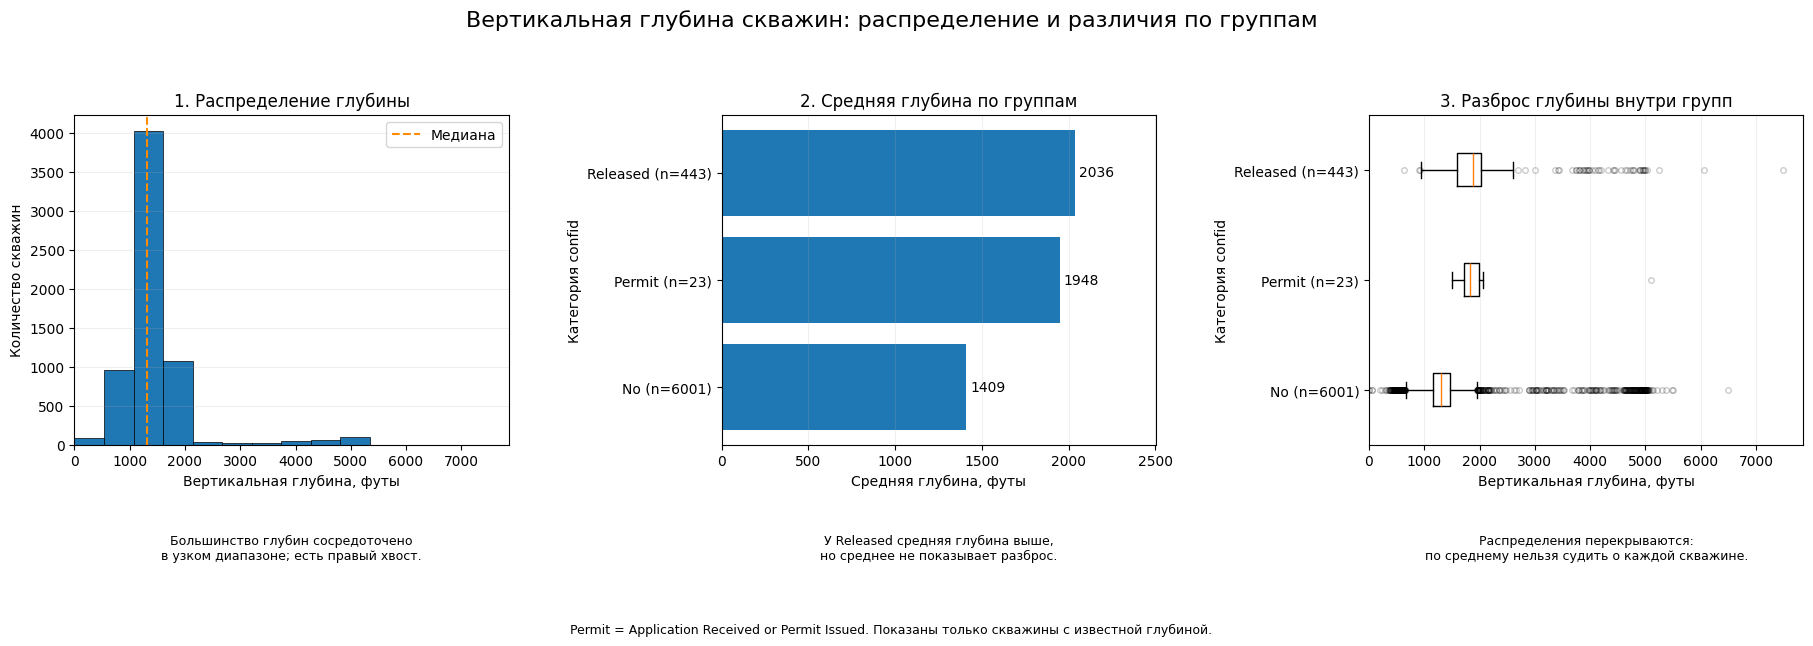

In [9]:
# Пункт 8: код

value_col = "True_vertical_depth"
group_col = "confid"
x8 = df[value_col].dropna()

# Данные для сравнения
data8 = df[[group_col, value_col]].dropna()

stats8 = (
    data8.groupby(group_col)[value_col]
    .agg(["count", "mean", "median"])
    .sort_values("mean")
)

names8 = list(stats8.index)
short_names8 = {
    "No": "No",
    "Released": "Released",
    "Application Received or Permit Issued": "Permit"
}
labels8 = [
    f"{short_names8[name]} (n={stats8.loc[name, 'count']})"
    for name in names8
]

# Проверяем, насколько группировка объясняет разброс
overall_mean8 = data8[value_col].mean()

ss_total8 = ((data8[value_col] - overall_mean8) ** 2).sum()

ss_between8 = (
    stats8["count"] * (stats8["mean"] - overall_mean8) ** 2
).sum()
eta8 = ss_between8 / ss_total8

print("Количество известных глубин:", len(x8))
print("Пропусков:", df[value_col].isna().sum())
print("\nСтатистика по группам:")
print(stats8.round(2))
print(f"\nEta²: {eta8:.4f}")
print(f"Объяснённый разброс: {eta8 * 100:.2f}%")

fig, axes = plt.subplots(1, 3, figsize=(19, 6.6))

fig.suptitle(
    "Вертикальная глубина скважин: распределение и различия по группам",
    fontsize=16
)

# График 1. Гистограмма
axes[0].hist(
    x8, bins="sturges",
    edgecolor="black", linewidth=0.5
)

axes[0].axvline(
    x8.median(),
    color="darkorange",
    linestyle="--",
    label="Медиана"
)

axes[0].set_title("1. Распределение глубины")
axes[0].set_xlabel("Вертикальная глубина, футы")
axes[0].set_ylabel("Количество скважин")
axes[0].set_xlim(left=0)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.2)

# График 2. Средние глубины
means8 = stats8["mean"].to_numpy()

bars8 = axes[1].barh(labels8, means8)

axes[1].bar_label(
    bars8, fmt="%.0f", padding=3
)

axes[1].set_title("2. Средняя глубина по группам")
axes[1].set_xlabel("Средняя глубина, футы")
axes[1].set_ylabel("Категория confid")
axes[1].set_xlim(0, means8.max() * 1.23)
axes[1].grid(axis="x", alpha=0.2)

# График 3. Ящики с усами
box_data8 = [
    data8.loc[data8[group_col] == name, value_col]
    for name in names8
]

axes[2].boxplot(
    box_data8,
    vert=False,
    flierprops={
        "markersize": 4,
        "alpha": 0.2
    }
)

axes[2].set_yticks(
    range(1, len(labels8) + 1),
    labels=labels8
)

axes[2].set_title("3. Разброс глубины внутри групп")
axes[2].set_xlabel("Вертикальная глубина, футы")
axes[2].set_ylabel("Категория confid")
axes[2].set_xlim(left=0)
axes[2].grid(axis="x", alpha=0.2)

captions8 = [
    "Большинство глубин сосредоточено\n"
    "в узком диапазоне; есть правый хвост.",

    "У Released средняя глубина выше,\n"
    "но среднее не показывает разброс.",

    "Распределения перекрываются:\n"
    "по среднему нельзя судить о каждой скважине."
]

for ax, caption in zip(axes, captions8):
    ax.text(
        0.5, -0.27, caption,
        transform=ax.transAxes,
        ha="center", va="top",
        fontsize=9
    )

fig.text(
    0.5, 0.035,
    "Permit = Application Received or Permit Issued. "
    "Показаны только скважины с известной глубиной.",
    ha="center",
    fontsize=9
)

fig.subplots_adjust(
    left=0.07, right=0.98,
    top=0.82, bottom=0.32,
    wspace=0.49
)

plt.show()


**Ответ.**


**1. Почему выбраны именно эти три графика?**

Я выбрала гистограмму вертикальной глубины, диаграмму средних по категориям confid и ящики с усами по тем же категориям.

Первый график показывает общее распределение глубин: большинство скважин имеет глубину около 1000–2000 футов, но встречаются и значительно более глубокие.

Второй график добавляет сравнение категорий. Средняя глубина скважин Released составляет 2035,93 фута, а No - 1408,69 фута.

Третий график показывает то, чего нет на диаграмме средних: медианы, разброс и выбросы. Распределения групп сильно перекрываются, поэтому высокая средняя глубина не означает, что каждая скважина одной категории глубже скважин другой.

Дополнительно коэффициент η² равен 0,0531, то есть группировка по confid объясняет только 5,31% общего разброса глубин.

**2. Какой график я не включила и почему?**

Я не включила точечную диаграмму связи True_vertical_depth и Measured_depth из пункта 3. Эти признаки почти полностью совпадают, поэтому большинство точек лежит на одной диагонали. Такой график полезен для проверки согласованности измерений, но меньше помогает заказчику понять распределение глубин и различия между категориями.

**3. Какого графика не хватает?**

Не хватает графика зависимости фактического объёма добычи от глубины скважины. Он позволил бы выяснить, связана ли большая глубина с большей продуктивностью.

В моём наборе нет показателя объёма добычи нефти или газа за определённый период. Поэтому по имеющимся графикам можно сравнивать глубины скважин, но нельзя сделать вывод об их реальной продуктивности. Для этого необходимо дополнительно получить сведения о фактической добыче за сопоставимый период эксплуатации.

## ○ Пункт 9. График, который вы забраковали

<sub>дополнительный пункт · 1 балл</sub>

Всего скважин: 6463
Глубины совпадают: 6454
Глубины различаются: 9


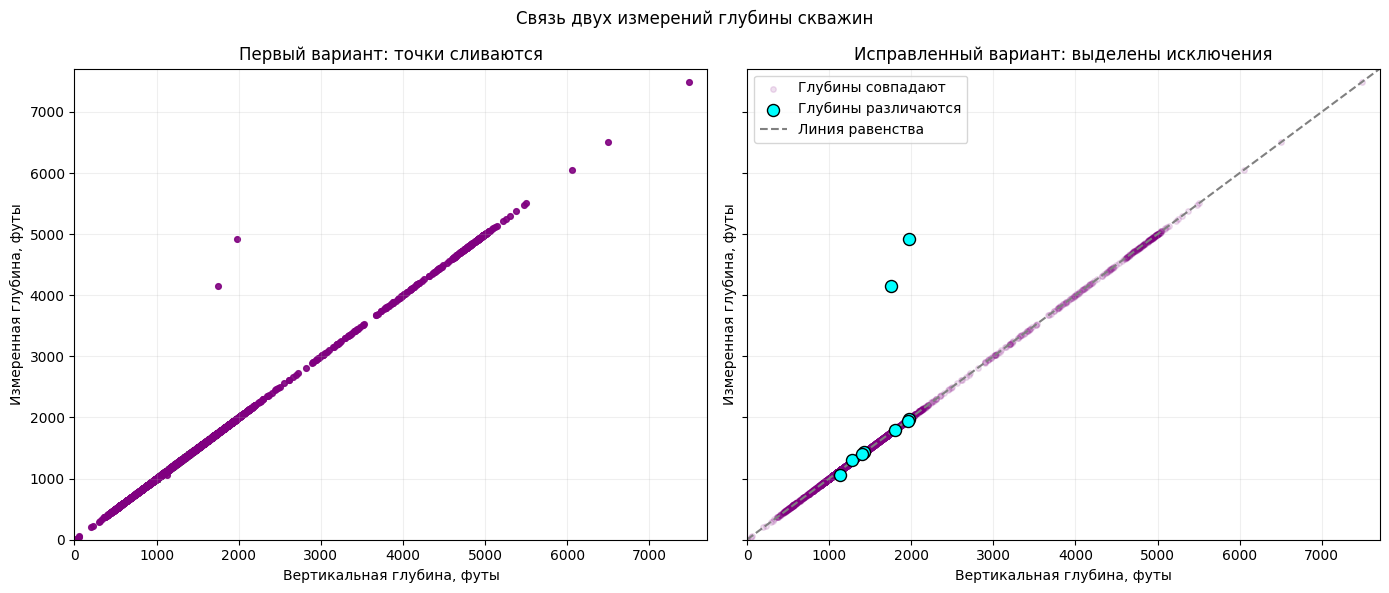

In [10]:

# Пункт 9. Код

x9 = "True_vertical_depth"
y9 = "Measured_depth"

data9 = df[[x9, y9]].dropna().copy()
data9["difference"] = (data9[y9] - data9[x9]).abs()

same9 = data9["difference"] == 0
different9 = data9["difference"] > 0

print("Всего скважин:", len(data9))
print("Глубины совпадают:", same9.sum())
print("Глубины различаются:", different9.sum())

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(14, 6), sharex=True, sharey=True
)
limit9 = max(data9[x9].max(), data9[y9].max()) * 1.03

# Первая попытка
ax1.scatter(
    data9[x9], data9[y9],
    color="purple", s=17, alpha=0.9
)
ax1.set_title("Первый вариант: точки сливаются")

# Исправленный вариант
ax2.scatter(
    data9.loc[same9, x9],
    data9.loc[same9, y9],
    color="purple", s=16, alpha=0.12,
    label="Глубины совпадают"
)

ax2.scatter(
    data9.loc[different9, x9],
    data9.loc[different9, y9],
    color="cyan", s=75,
    edgecolors="black",
    label="Глубины различаются",
    zorder=3
)

ax2.plot(
    [0, limit9], [0, limit9],
    "--", color="gray", label="Линия равенства"
)

ax2.set_title("Исправленный вариант: выделены исключения")
ax2.legend()

for ax in (ax1, ax2):
    ax.set_xlabel("Вертикальная глубина, футы")
    ax.set_ylabel("Измеренная глубина, футы")
    ax.set_xlim(0, limit9)
    ax.set_ylim(0, limit9)
    ax.grid(alpha=0.2)

fig.suptitle("Связь двух измерений глубины скважин")
plt.tight_layout()
plt.show()


**Ответ.**

> В пункте 3 я сначала построила обычную точечную диаграмму зависимости Measured_depth от True_vertical_depth. Однако из-за большого количества совпадающих значений точки накладывались друг на друга, и график выглядел как одна диагональная линия. Я решила изменить график, сделала совпадающие значения полупрозрачными, а скважины с различающимися глубинами выделила отдельным цветом. Так стало видно, что из 6463 скважин у 6454 глубины совпадают, а у 9 имеются расхождения. После построения второго графика я поняла, что высокая корреляция не означает полного совпадения значений. Например, у отдельных скважин расхождение достигает 2949 футов. Поэтому при анализе важно обращать внимание не только на общую закономерность, но и на отдельные отклонения, которые могут быть связаны с особенностями скважины или ошибками данных.

---

## Перед сдачей

- [ ] Kernel → Restart & Run All прошёл без ошибок
- [ ] выводы ячеек сохранены в файле
- [ ] у каждого пункта есть письменный ответ
- [ ] на каждом графике подписаны обе оси
- [ ] в первой ячейке указаны фамилия, группа и номер варианта
- [ ] Контест по этому заданию принят — без него работа не рассматривается